In [15]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

df.describe(include = "all")


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
count,920.000000,920.000000,920,920,920,860.000000,718.000000,830,918,865.000000,865,858.000000,611,309.000000,434,920.000000
unique,NaN,NaN,2,4,4,NaN,NaN,2,3,NaN,2,NaN,3,NaN,3,NaN
top,NaN,NaN,Male,Cleveland,asymptomatic,NaN,NaN,False,normal,NaN,False,NaN,flat,NaN,normal,NaN
freq,NaN,NaN,726,304,496,NaN,NaN,692,551,NaN,528,NaN,345,NaN,196,NaN
mean,460.500000,53.510870,NaN,NaN,NaN,132.286047,246.832869,NaN,NaN,137.545665,NaN,0.878788,NaN,0.676375,NaN,0.553261
std,265.725422,9.424685,NaN,NaN,NaN,18.536175,58.527062,NaN,NaN,25.926276,NaN,1.091226,NaN,0.935653,NaN,0.497426
min,1.000000,28.000000,NaN,NaN,NaN,80.000000,85.000000,NaN,NaN,60.000000,NaN,-2.600000,NaN,0.000000,NaN,0.000000
25%,230.750000,47.000000,NaN,NaN,NaN,120.000000,210.000000,NaN,NaN,120.000000,NaN,0.000000,NaN,0.000000,NaN,0.000000
50%,460.500000,54.000000,NaN,NaN,NaN,130.000000,239.500000,NaN,NaN,140.000000,NaN,0.500000,NaN,0.000000,NaN,1.000000
75%,690.250000,60.000000,NaN,NaN,NaN,140.000000,276.750000,NaN,NaN,157.000000,NaN,1.500000,NaN,1.000000,NaN,1.000000


In [29]:
from preprocessing import preprocessor, numerical_features, categorical_features
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

X = df.drop(columns=["id", "dataset", "num"])
y = df["num"]

# Convert categorical columns to consistent string values

for col in categorical_features:
    X[col] = X[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
    
knn_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",KNeighborsClassifier(n_neighbors = 5))
])

knn_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [30]:
y_pred_knn = knn_pipeline.predict(X_test)

y_prob_knn = knn_pipeline.predict_proba(X_test)[:,1]

In [32]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("F1 Score:", f1_score(y_test, y_pred_knn))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

Accuracy: 0.8586956521739131
Precision: 0.8725490196078431
Recall: 0.8725490196078431
F1 Score: 0.8725490196078431
ROC-AUC: 0.8906025824964132

Confusion Matrix:
[[69 13]
 [13 89]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84        82
           1       0.87      0.87      0.87       102

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184



In [45]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)

In [40]:
k_values = [1, 4, 7, 10, 13, 16, 19, 22, 25, 28, 31]

In [47]:
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

results = []

for k in k_values:

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    results.append({
        "K": k,
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

knn_results = pd.DataFrame(results)

knn_results

,K,Mean ROC-AUC,Std ROC-AUC
0,1,0.760906,0.046118
1,4,0.855147,0.026981
2,7,0.868586,0.020798
3,10,0.874110,0.023477
4,13,0.878809,0.023621
5,16,0.880740,0.021705
6,19,0.883585,0.020191
7,22,0.886335,0.020123
8,25,0.888063,0.018106
9,28,0.888834,0.020436


In [50]:
best_index = knn_results["Mean ROC-AUC"].idxmax()

best_k = int(knn_results.loc[best_index, "K"])
best_score = knn_results.loc[best_index, "Mean ROC-AUC"]

print("Best K:", best_k)
print("Best Mean CV ROC-AUC:", best_score)

Best K: 28
Best Mean CV ROC-AUC: 0.8888344847965444


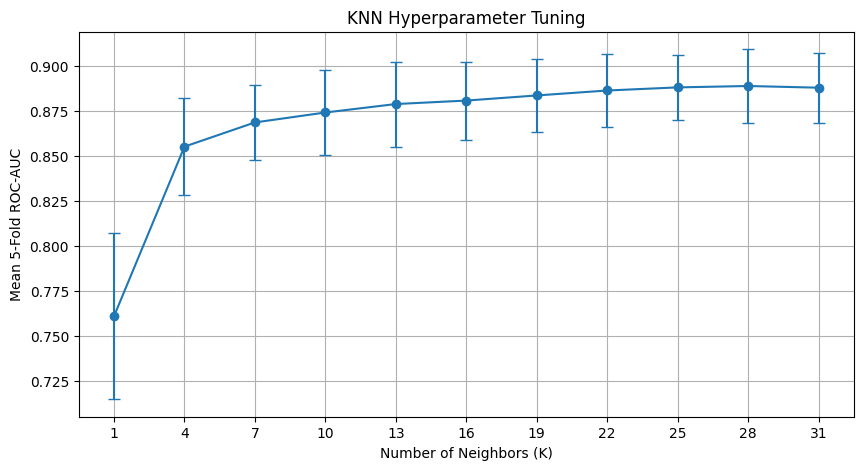

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.errorbar(
    knn_results["K"],
    knn_results["Mean ROC-AUC"],
    
    yerr=knn_results["Std ROC-AUC"],
    marker="o",
    capsize=4
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean 5-Fold ROC-AUC")
plt.title("KNN Hyperparameter Tuning")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [56]:
knn_16 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(n_neighbors=16))
])

knn_28 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(n_neighbors=28))
])

knn_16.fit(X_train, y_train)
knn_28.fit(X_train, y_train)

prob_16 = knn_16.predict_proba(X_test)[:, 1]
prob_28 = knn_28.predict_proba(X_test)[:, 1]

print("K=16 Test ROC-AUC:", roc_auc_score(y_test, prob_16))
print("K=28 Test ROC-AUC:", roc_auc_score(y_test, prob_28))

K=16 Test ROC-AUC: 0.9029770444763271
K=28 Test ROC-AUC: 0.9001673840267813


In [61]:
final_knn = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(n_neighbors=16))
])

final_knn.fit(X_train, y_train)

y_pred_knn = final_knn.predict(X_test)
y_prob_knn = final_knn.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("F1 Score:", f1_score(y_test, y_pred_knn))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

Accuracy: 0.8478260869565217
Precision: 0.87
Recall: 0.8529411764705882
F1 Score: 0.8613861386138614
ROC-AUC: 0.9029770444763271

Confusion Matrix:
[[69 13]
 [15 87]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.84      0.83        82
           1       0.87      0.85      0.86       102

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184



In [71]:
import joblib
joblib.dump(final_knn, "D:/1_Python Programmes/Projects/HDD/models/heart_disease_knn.pkl")


['D:/1_Python Programmes/Projects/HDD/models/heart_disease_knn.pkl']

In [84]:
logreg_model = joblib.load(
    "D:/1_Python Programmes/Projects/HDD/models/heart_disease_lr.pkl"
)

models = {
    "Logistic Regression": logreg_model,
    "KNN (K=16)": final_knn
}

comparison = []

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(y_test, predictions)
    tn, fp, fn, tp = cm.ravel()

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(comparison).set_index("Model")

comparison_df.round(4)

,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
Model,,,,,,
Logistic Regression,0.8533,0.8505,0.8922,0.8049,0.8708,0.9143
KNN (K=16),0.8478,0.8700,0.8529,0.8415,0.8614,0.9030


In [86]:
# import joblib
# import os

# knn_artifact = {
#     "model": final_knn,
#     "algorithm": "K-Nearest Neighbors",
#     "best_k": 16,
#     "threshold": 0.5,
#     "metrics": knn_metrics,
#     "cv_roc_auc": best_score
# }

# joblib.dump(
#     knn_artifact,
#     "models/knn_model.pkl"
# )

In [88]:
# import os

# comparison_df.to_csv(
#     "reports/model_comparison.csv",
#     index=True,
#     index_label="Model"
# )

# print("Model comparison saved successfully!")